# Is the Exoplanet Catalogue a Map of Planets — or of Our Telescopes?

**Research question.** More than six thousand exoplanets have now been confirmed. Does the shape of that catalogue describe the underlying population of planets, or the instruments that found them?

**Data.** NASA Exoplanet Archive, Planetary Systems (`ps`) table, one row per confirmed planet (`default_flag = 1`). Snapshot taken on 20 October 2026. Retrieved through the Archive's TAP service; the exact query is reproduced at the end of this notebook.

**What this notebook delivers.** Three figures and three summary tables, all computed from `data/ps.csv`, followed by findings and an honest statement of what the data cannot support.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.dpi": 115,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 9.5,
    "axes.titlesize": 11,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8,
    "legend.frameon": False,
})

DATA = Path("data/ps.csv")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

df = pd.read_csv(DATA, na_values=["", "\\N"])
print(f"{len(df):,} confirmed planets, {df.shape[1]} columns")
df.head(3)

6,451 confirmed planets, 12 columns


,pl_name,hostname,disc_year,discoverymethod,disc_facility,pl_orbper,pl_rade,pl_bmasse,pl_orbsmax,st_teff,st_mass,sy_dist
0,WASP-43 b,WASP-43,2011,Transit,SuperWASP,0.813475,10.424000,565.71400,0.01420,4400.0,0.580,86.7467
1,KELT-4 A b,KELT-4 A,2016,Transit,KELT,2.989593,19.044091,286.68266,0.04317,6206.0,1.201,218.0500
2,WASP-80 b,WASP-80,2012,Transit,SuperWASP,3.067852,11.197791,170.99254,0.03440,4143.0,0.577,49.7876


## 1. What is in the table

Eleven detection methods, 1992–2026, and a great deal of missing measurement. The missingness is not noise to be cleaned away here: it is the first sign that each method records a different kind of planet.

In [2]:
print(f"Planets:     {len(df):,}")
print(f"Host stars:  {df['hostname'].nunique():,}")
print(f"Years:       {df['disc_year'].min()}-{df['disc_year'].max()}")
print(f"Methods:     {df['discoverymethod'].nunique()}")

missing = (
    df.isna().sum().rename("missing").to_frame()
    .assign(share_pct=lambda d: (d["missing"] / len(df) * 100).round(1))
    .sort_values("missing", ascending=False)
)
missing[missing["missing"] > 0]

Planets:     6,451
Host stars:  4,847
Years:       1992-2026
Methods:     11


,missing,share_pct
pl_bmasse,3263,50.6
pl_orbsmax,2496,38.7
pl_rade,1625,25.2
st_mass,877,13.6
st_teff,773,12.0
pl_orbper,368,5.7
sy_dist,128,2.0


In [3]:
counts = (
    df["discoverymethod"].value_counts()
    .rename_axis("method").reset_index(name="planets")
)
counts["share_pct"] = (counts["planets"] / len(df) * 100).round(1)
counts

,method,planets,share_pct
0,Transit,4785,74.2
1,Radial Velocity,1204,18.7
2,Microlensing,292,4.5
3,Imaging,98,1.5
4,Transit Timing Variations,29,0.4
5,Eclipse Timing Variations,17,0.3
6,Orbital Brightness Modulation,9,0.1
7,Pulsar Timing,8,0.1
8,Astrometry,6,0.1
9,Pulsation Timing Variations,2,0.0


## 2. The catalogue is dominated by one instrument, and by two events

Transit photometry supplies roughly three quarters of everything we know. The record is not a slow accumulation either: it jumps when a survey starts delivering. Kepler's bulk confirmations land in 2014–2016, and TESS takes over after 2018.

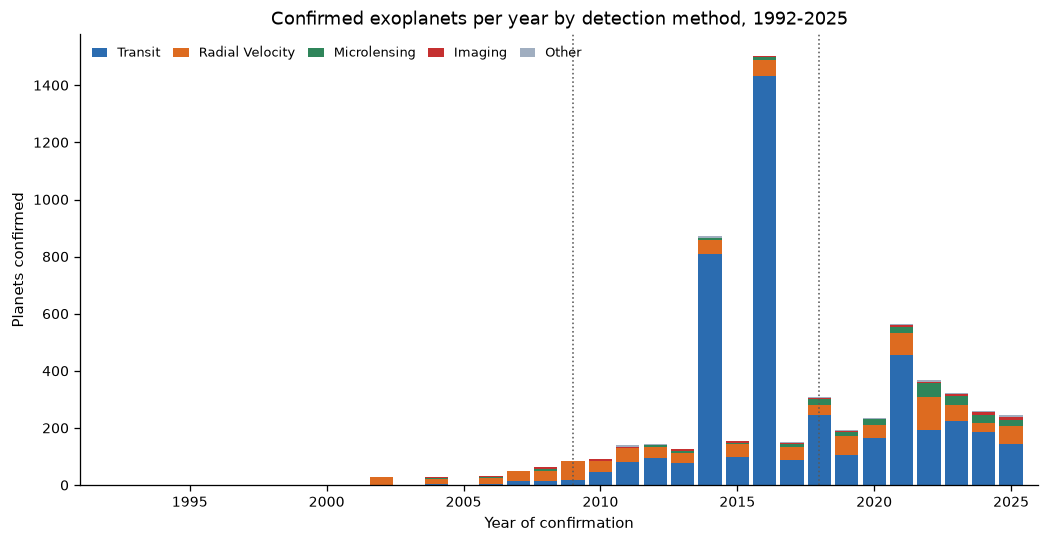

Transit share of the catalogue: 74.2%
Planets confirmed in 2016: 1,504


In [4]:
GROUP = {
    "Transit": "Transit",
    "Radial Velocity": "Radial Velocity",
    "Microlensing": "Microlensing",
    "Imaging": "Imaging",
}
df["method_group"] = df["discoverymethod"].map(GROUP).fillna("Other")

COLORS = {
    "Transit": "#2b6cb0",
    "Radial Velocity": "#dd6b20",
    "Microlensing": "#2f855a",
    "Imaging": "#c53030",
    "Other": "#a0aec0",
}

# 2026 is a partial year at snapshot time, so the yearly chart stops at 2025.
years = df[df["disc_year"] <= 2025]
pivot = (
    years.pivot_table(index="disc_year", columns="method_group",
                      values="pl_name", aggfunc="count")
    .reindex(columns=list(COLORS), fill_value=0)
    .reindex(range(1992, 2026), fill_value=0)
)

fig, ax = plt.subplots(figsize=(9.2, 4.8))
bottom = np.zeros(len(pivot))
for col in pivot.columns:
    ax.bar(pivot.index, pivot[col], bottom=bottom, label=col,
           color=COLORS[col], width=0.85)
    bottom += pivot[col].to_numpy()

ymax = bottom.max()
for x, label in [(2009, "Kepler launch"), (2018, "TESS launch")]:
    ax.axvline(x, color="0.35", ls=":", lw=1)
    ax.text(x + 0.5, ymax * 0.93, label, fontsize=7.5, color="0.35")

ax.set_xlim(1991, 2026)
ax.set_xlabel("Year of confirmation")
ax.set_ylabel("Planets confirmed")
ax.set_title("Confirmed exoplanets per year by detection method, 1992-2025")
ax.legend(ncol=5, loc="upper left", handlelength=1.2, columnspacing=1.0)
fig.tight_layout()
fig.savefig(FIG / "fig1_discoveries_by_method.png", bbox_inches="tight")
plt.show()

print(f"Transit share of the catalogue: {100 * (df['discoverymethod'] == 'Transit').mean():.1f}%")
print(f"Planets confirmed in 2016: {int((df['disc_year'] == 2016).sum()):,}")

Read the bars as a history of instruments, not of planet formation. The 2014–2016 spike is not a burst of planet birth; it is the moment one pipeline validated thousands of candidates at once. Any claim of the form "planet discoveries are accelerating" has to survive this chart first.

## 3. Two windows on the same catalogue

Size and mass are measured by different techniques, and each one sees a different slice of the population. The left panel below can only contain planets that have a measured radius — almost all of them transits. The right panel is dominated by radial-velocity planets, which have a mass but usually no radius.

pl_rade: 4,796 planets with both a period and this measurement
pl_bmasse: 2,831 planets with both a period and this measurement


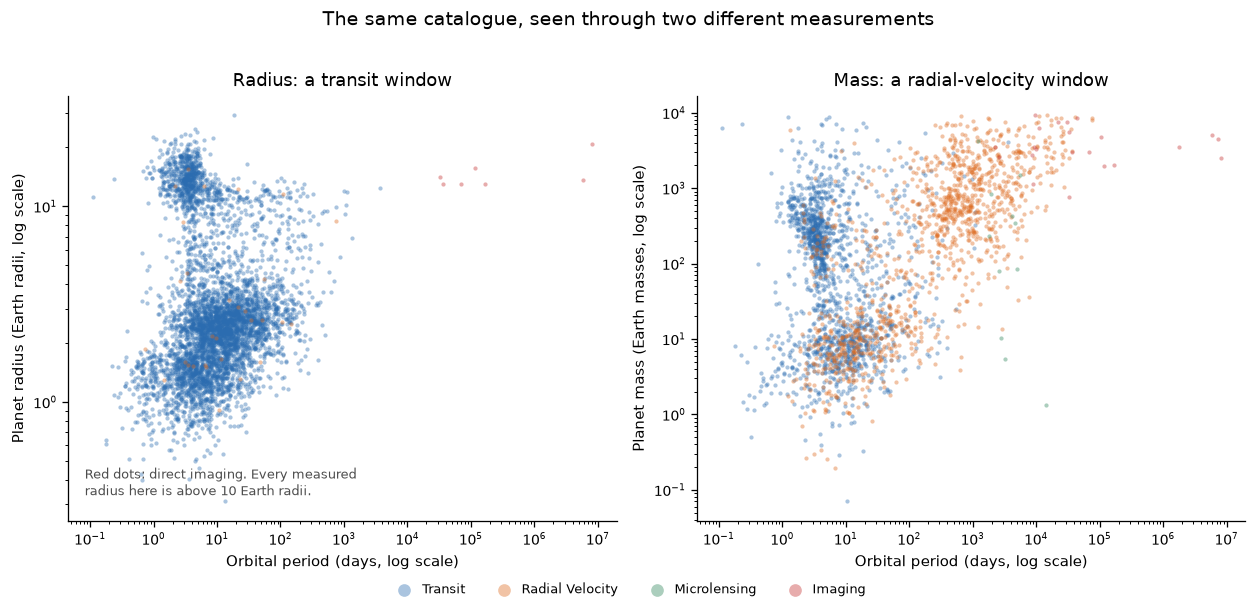

In [5]:
methods = ["Transit", "Radial Velocity", "Microlensing", "Imaging"]
panel_specs = [
    ("pl_rade", "Planet radius (Earth radii, log scale)", "Radius: a transit window"),
    ("pl_bmasse", "Planet mass (Earth masses, log scale)", "Mass: a radial-velocity window"),
]

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.9))
for ax, (ycol, ylabel, title) in zip(axes, panel_specs):
    sub = df.dropna(subset=["pl_orbper", ycol])
    for m in methods:
        s = sub[sub["discoverymethod"] == m]
        if s.empty:
            continue
        ax.scatter(s["pl_orbper"], s[ycol], s=7, alpha=0.4,
                   color=COLORS[m], label=m, linewidths=0)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Orbital period (days, log scale)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    print(f"{ycol}: {len(sub):,} planets with both a period and this measurement")

axes[0].text(0.03, 0.05,
             "Red dots: direct imaging. Every measured\nradius here is above 10 Earth radii.",
             transform=axes[0].transAxes, fontsize=8, color="0.3", va="bottom")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, -0.04), markerscale=3, handletextpad=0.4)
fig.suptitle("The same catalogue, seen through two different measurements", fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig(FIG / "fig2_radius_and_mass.png", bbox_inches="tight")
plt.show()

The asymmetry is the result. Transits deliver a radius for 99.5% of their planets but a mass for only 32%; radial velocity delivers a mass for 99.6% of its planets and a radius for 2.5% of them. A scatter plot of radius therefore looks like a catalogue of small planets, and a scatter plot of mass looks like a catalogue of giants — from the same underlying table.

In [6]:
summary = (
    df.groupby("discoverymethod")
    .agg(planets=("pl_name", "size"),
         with_radius=("pl_rade", "count"),
         with_mass=("pl_bmasse", "count"),
         with_period=("pl_orbper", "count"),
         median_period_d=("pl_orbper", "median"),
         median_radius_re=("pl_rade", "median"),
         median_mass_me=("pl_bmasse", "median"))
    .sort_values("planets", ascending=False)
    .round(2)
)
summary["radius_pct"] = (summary["with_radius"] / summary["planets"] * 100).round(1)
summary["mass_pct"] = (summary["with_mass"] / summary["planets"] * 100).round(1)
summary

,planets,with_radius,with_mass,with_period,median_period_d,median_radius_re,median_mass_me,radius_pct,mass_pct
discoverymethod,,,,,,,,,
Transit,4785,4760,1534,4778,7.98,2.45,81.85,99.5,32.1
Radial Velocity,1204,30,1199,1202,304.15,2.59,292.40,2.5,99.6
Microlensing,292,0,292,11,3285.00,NaN,195.00,0.0,100.0
Imaging,98,30,94,22,33100.00,15.19,3893.41,30.6,95.9
Transit Timing Variations,29,3,29,29,41.29,10.40,69.92,10.3,100.0
Eclipse Timing Variations,17,0,17,17,3160.00,NaN,1760.78,0.0,100.0
Orbital Brightness Modulation,9,3,6,9,0.81,0.87,397.29,33.3,66.7
Pulsar Timing,8,0,8,7,25.26,NaN,128.47,0.0,100.0
Astrometry,6,0,6,6,334.76,NaN,5021.69,0.0,100.0


## 4. Blind spots, quantified

The two panels below compare what each method typically delivers: how far from its star it looks, and how often it can measure a size at all. Only the three largest methods are shown; the remaining eight are omitted for readability — including microlensing, which has 292 confirmed planets but not a single measured radius.

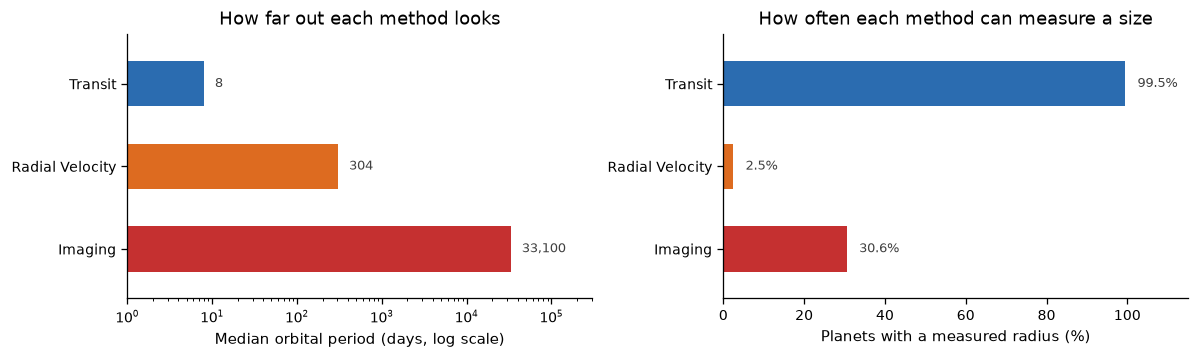

In [7]:
shown = ["Transit", "Radial Velocity", "Imaging"]
sub = summary.loc[shown]
y = np.arange(len(sub))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2))

axes[0].barh(y, sub["median_period_d"], color=[COLORS[m] for m in sub.index], height=0.55)
axes[0].set_yticks(y)
axes[0].set_yticklabels(sub.index)
axes[0].set_xscale("log")
axes[0].set_xlim(1, 3e5)
axes[0].set_xlabel("Median orbital period (days, log scale)")
axes[0].set_title("How far out each method looks")

axes[1].barh(y, sub["radius_pct"], color=[COLORS[m] for m in sub.index], height=0.55)
axes[1].set_yticks(y)
axes[1].set_yticklabels(sub.index)
axes[1].set_xlim(0, 115)
axes[1].set_xlabel("Planets with a measured radius (%)")
axes[1].set_title("How often each method can measure a size")

for yi, (method, row) in enumerate(sub.iterrows()):
    axes[0].text(row["median_period_d"] * 1.35, yi, f'{row["median_period_d"]:,.0f}',
                 va="center", fontsize=8, color="0.25")
    axes[1].text(row["radius_pct"] + 3, yi, f'{row["radius_pct"]:.1f}%',
                 va="center", fontsize=8, color="0.25")

for ax in axes:
    ax.set_ylim(len(sub) - 0.4, -0.6)

fig.tight_layout()
fig.savefig(FIG / "fig3_method_blind_spots.png", bbox_inches="tight")
plt.show()

## Findings

1. **This is one instrument's view.** Transit photometry accounts for 74% of confirmed planets (4,785 of 6,451), and 1,504 planets arrived in 2016 alone.
2. **Each method reaches a different distance.** Median orbital period is 8 days for transits, 304 days for radial velocity and 33,100 days — roughly 90 years — for direct imaging, whose median rests on 22 planets with a measured period.
3. **Size is the most method-bound property of all.** Transits have a radius for 99.5% of their planets; radial velocity for 2.5%; microlensing for none. The 30 imaged planets that do have a radius are all larger than 10 Earth radii, with a median of 15.2.

Together these mean that statements such as "the most common planet is ..." describe the detection pipeline at least as much as they describe the Galaxy.

## Limitation

The catalogue contains only *confirmed* planets, and confirmation is not a random process: it depends on follow-up telescope time, which is allocated unevenly across methods and years. There is no correction for the number of stars observed or the sensitivity actually achieved in each survey, and 25% of rows have no radius while 51% have no mass. The distributions above are therefore shaped by selection and should be read as lower bounds, not as an unbiased census of planets.

## Reproducing this analysis

```bash
pip install -r requirements.txt
jupyter lab analysis.ipynb
```

The notebook reads `data/ps.csv`, which is included in the repository, so it runs offline. The snapshot was retrieved on 20 October 2026 with:

```sql
SELECT pl_name, hostname, disc_year, discoverymethod, disc_facility,
       pl_orbper, pl_rade, pl_bmasse, pl_orbsmax, st_teff, st_mass, sy_dist
FROM ps
WHERE default_flag = 1
```

through `https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=...&format=csv`.

Data: NASA Exoplanet Archive, operated by Caltech/IPAC under contract with NASA. Acknowledgment: *This research has made use of the NASA Exoplanet Archive, which is operated by the California Institute of Technology, under contract with the National Aeronautics and Space Administration under the Exoplanet Exploration Program.*